In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd

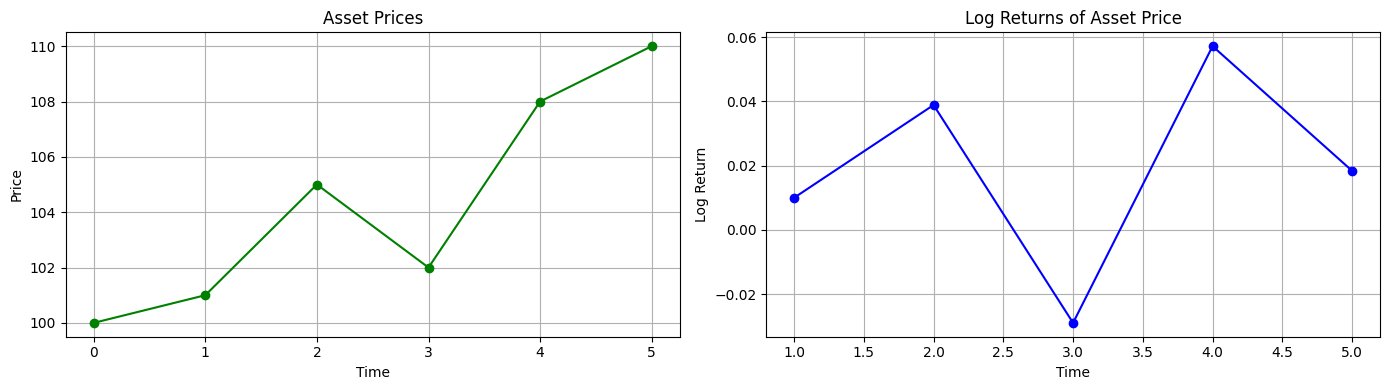

In [3]:
# Example price data (you can replace this with your own)
prices = np.array([100, 101, 105, 102, 108, 110], dtype=float)

# Compute log returns: ln(P_t / P_{t-1})
log_returns = np.log(prices[1:] / prices[:-1])

# Plot prices and log returns side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Plot original prices
axes[0].plot(range(len(prices)), prices, marker='o', linestyle='-', color='g')
axes[0].set_title("Asset Prices")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Price")
axes[0].grid(True)

# Plot log returns
axes[1].plot(range(1, len(prices)), log_returns, marker='o', linestyle='-', color='b')
axes[1].set_title("Log Returns of Asset Price")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Log Return")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [4]:
random_price = np.random.choice([-1, 1], size=400)
prod = torch.cumsum(torch.tensor(random_price), dim = 0)

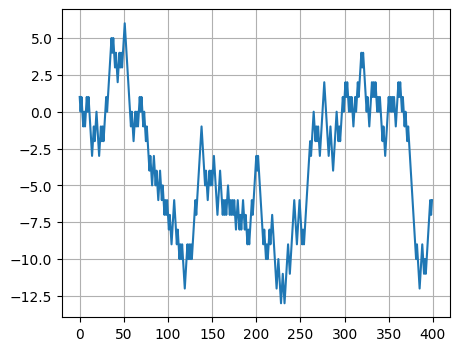

In [5]:
plt.figure(figsize=(5, 4))
plt.plot(prod.numpy())
plt.grid(True)

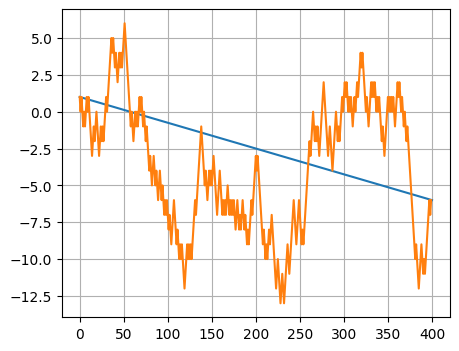

In [6]:
coor = [(0, prod[0].item()), (len(prod), prod[-1].item())]

x, y = zip(*coor)

plt.figure(figsize=(5, 4))
plt.plot(x, y)
plt.plot(prod.numpy())
plt.grid(True)


In [7]:
# This is one correct way to calculate the mean of the series using pandas
prod.float().mean()

tensor(-3.6800)

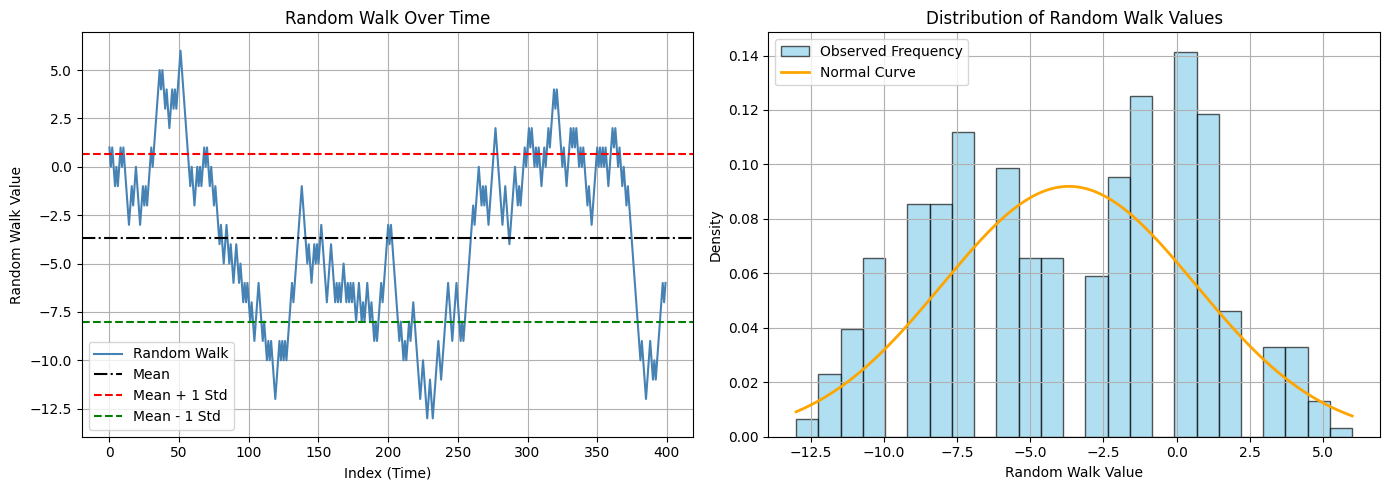

In [8]:
# Calculate standard deviation
from scipy.stats import norm

prod_np = prod.numpy()

# Manual sample standard deviation so it matches torch.std()
temp = torch.tensor(0.0)
mean_t = prod.float().mean()
for i in range(len(prod)):
    temp += (prod[i].float() - mean_t) ** 2
std_dev_t = torch.sqrt(temp / (len(prod) - 1))

mean = mean_t.item()
std_dev = std_dev_t.item()
indices = np.arange(len(prod_np))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: the random walk as a time series
axes[0].plot(indices, prod_np, color="steelblue", label="Random Walk")
axes[0].axhline(mean, color="black", linestyle="-.", label="Mean")
axes[0].axhline(mean + std_dev, color="red", linestyle="--", label="Mean + 1 Std")
axes[0].axhline(mean - std_dev, color="green", linestyle="--", label="Mean - 1 Std")
axes[0].set_title("Random Walk Over Time")
axes[0].set_xlabel("Index (Time)")
axes[0].set_ylabel("Random Walk Value")
axes[0].grid(True)
axes[0].legend()

# Right: how often each value appears, with a normal curve on top
axes[1].hist(prod_np, bins=25, density=True, alpha=0.65, color="skyblue", edgecolor="black", label="Observed Frequency")
x_bell = np.linspace(prod_np.min(), prod_np.max(), 400)
axes[1].plot(x_bell, norm.pdf(x_bell, loc=mean, scale=std_dev), color="orange", linewidth=2, label="Normal Curve")
axes[1].set_title("Distribution of Random Walk Values")
axes[1].set_xlabel("Random Walk Value")
axes[1].set_ylabel("Density")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

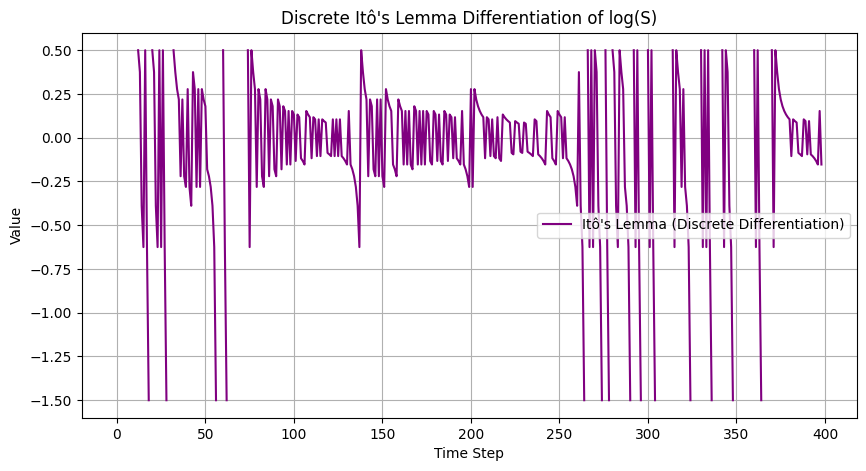

In [9]:
# Differentiate using Itô's lemma and plot the result

# Suppose prod is the (discrete) sample path of an Itô process S_t (e.g., geometric Brownian motion S_t)
# Use finite differences as the discrete analog of dS_t
# Itô's lemma for f(S) with f(x) = log(x): d(log(S_t)) = (1/S_t) dS_t - (1/2)(1/S_t^2) (dS_t)^2

# We'll use finite differences to approximate dS_t
S = prod.float()
dS = S[1:] - S[:-1]
S_mid = S[:-1]  # use the "left" endpoint for each interval

# Discrete Ito's lemma for log(S):
ito_diff = (1/S_mid) * dS - 0.5 * (1/S_mid**2) * (dS**2)

# Plot the 'differentiated' function (increments of log(S)), which should resemble log returns
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ito_diff.numpy(), label="Itô's Lemma (Discrete Differentiation)", color="purple")
ax.set_title("Discrete Itô's Lemma Differentiation of log(S)")
ax.set_xlabel("Time Step")
ax.set_ylabel("Value")
ax.grid(True)
ax.legend()
plt.show()

In [10]:
import numpy as np

def lmsr_cost(q, b):
    """
    LMSR cost function.
    q: array of quantities for each outcome
    b: liquidity parameter
    """
    return b * np.log(np.sum(np.exp(np.array(q) / b)))
def lmsr_price(q, b, outcome_index):
    """
    Current price of a specific outcome.
    This is the softmax function.
    """
    q = np.array(q)
    exp_q = np.exp(q / b)
    return exp_q[outcome_index] / np.sum(exp_q)
def cost_of_trade(q_before, q_after, b):
    """
    How much does a trade cost?
    Difference in cost function before and after.
    """
    return lmsr_cost(q_after, b) - lmsr_cost(q_before, b)
# Starting state: nobody has bought anything
q = [0, 0]
b = 100
# Current prices
p_yes = lmsr_price(q, b, 0)
p_no = lmsr_price(q, b, 1)
print(f"Initial price of YES: {p_yes:.4f}")  # 0.5000
print(f"Initial price of NO:  {p_no:.4f}")   # 0.5000
print(f"Sum: {p_yes + p_no:.4f}")             # 1.0000

Initial price of YES: 0.5000
Initial price of NO:  0.5000
Sum: 1.0000


In [11]:
q_before = [0, 0]
q_after = [50, 0]

# What did that cost them?
trade_cost = cost_of_trade(q_before, q_after, b)
print(f"Cost of buying 50 YES shares: ${trade_cost:.2f}")
# What are prices now?
p_yes_new = lmsr_price(q_after, b, 0)
p_no_new = lmsr_price(q_after, b, 1)
print(f"New price of YES: {p_yes_new:.4f}")  # 0.6225
print(f"New price of NO:  {p_no_new:.4f}")   # 0.3775

Cost of buying 50 YES shares: $28.09
New price of YES: 0.6225
New price of NO:  0.3775


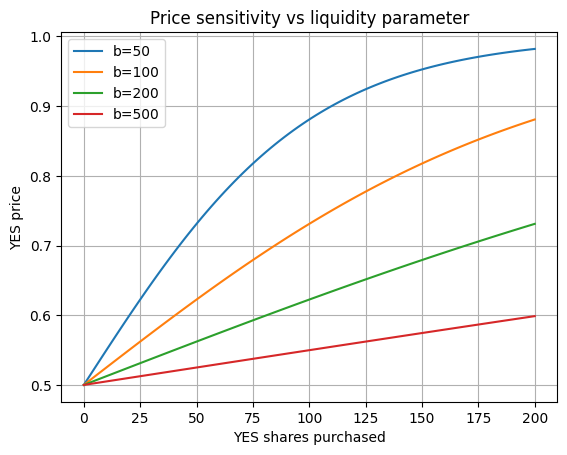

In [12]:
import matplotlib.pyplot as plt

def show_price_sensitivity(b_values):
    shares_bought = np.linspace(0, 200, 100)
    
    for b in b_values:
        prices = []
        for s in shares_bought:
            q = [s, 0]
            prices.append(lmsr_price(q, b, 0))
        plt.plot(shares_bought, prices, label=f'b={b}')
    
    plt.xlabel('YES shares purchased')
    plt.ylabel('YES price')
    plt.title('Price sensitivity vs liquidity parameter')
    plt.legend()
    plt.grid(True)
    plt.show()
show_price_sensitivity([50, 100, 200, 500])

In [13]:
b = 100_000
n = 2  # binary market

max_loss = b * np.log(n)
print(f"Maximum market maker loss: ${max_loss:,.0f}")
# Maximum market maker loss: $69,315

Maximum market maker loss: $69,315


In [14]:
def expected_value(market_price, true_probability, shares=1):
    """
    Expected value of buying one YES share.
    
    market_price: what you pay per share (between 0 and 1)
    true_probability: your estimate of the true probability
    shares: number of shares
    
    A YES share pays $1 if YES wins, $0 if NO wins.
    """
    # If YES wins (probability = true_prob): you gain (1 - market_price)
    # If NO wins (probability = 1 - true_prob): you lose market_price
    
    ev = (true_probability * (1 - market_price) - 
          (1 - true_probability) * market_price)
    
    return ev * shares

# Example: market says 40% chance, you think it's 60%
market_price = 0.40
your_estimate = 0.60
ev = expected_value(market_price, your_estimate)
print(f"Expected value per share: ${ev:.3f}")
# Expected value per share: $0.200
# That's a 20 cent edge per dollar risked
# In Kelly terms, this is a significant edge

Expected value per share: $0.200


In [15]:
def simulate_buy_impact(initial_q, shares_to_buy, b, outcome=0, steps=10):
    """
    Simulate buying a large position incrementally.
    Shows how average fill price degrades with size.
    """
    q = list(initial_q)
    total_cost = 0
    total_shares = 0
    prices_paid = []
    
    shares_per_step = shares_to_buy / steps
    
    for step in range(steps):
        price_before = lmsr_price(q, b, outcome)
        
        q_after = q.copy()
        q_after[outcome] += shares_per_step
        
        step_cost = cost_of_trade(q, q_after, b)
        total_cost += step_cost
        total_shares += shares_per_step
        prices_paid.append(step_cost / shares_per_step)
        
        q = q_after
    
    avg_fill = total_cost / total_shares
    final_price = lmsr_price(q, b, outcome)
    
    print(f"Shares bought: {shares_to_buy}")
    print(f"Starting price: {lmsr_price(initial_q, b, outcome):.4f}")
    print(f"Average fill price: {avg_fill:.4f}")
    print(f"Final price: {final_price:.4f}")
    print(f"Total cost: ${total_cost:.2f}")
    print(f"Price impact: {final_price - lmsr_price(initial_q, b, outcome):.4f}")
    
    return avg_fill
# Starting at even odds, buying 200 shares with b=100
simulate_buy_impact([0, 0], 200, b=100, outcome=0)

Shares bought: 200
Starting price: 0.5000
Average fill price: 0.7169
Final price: 0.8808
Total cost: $143.38
Price impact: 0.3808


np.float64(0.7168904152415138)

In [16]:
def analyze_market(
    current_q,          # current quantity vector [q_yes, q_no]
    b,                  # liquidity parameter
    your_probability,   # your estimate of YES probability
    max_shares=100      # maximum shares to consider buying
):
    """
    Given a market state and your probability estimate,
    calculate whether there's an edge and how much to buy.
    """
    
    current_price = lmsr_price(current_q, b, 0)
    edge = your_probability - current_price
    
    print(f"Market price: {current_price:.4f}")
    print(f"Your estimate: {your_probability:.4f}")
    print(f"Raw edge: {edge:.4f}")
    
    if abs(edge) < 0.02:
        print("Edge too small — no trade")
        return
    
    direction = 0 if edge > 0 else 1  # buy YES if positive edge, NO if negative
    direction_name = "YES" if direction == 0 else "NO"
    
    # Calculate EV at different sizes
    print(f"\nBuying {direction_name}:")
    print(f"{'Shares':>8} {'Avg Fill':>10} {'Total EV':>10}")
    
    q = list(current_q)
    total_cost = 0
    
    for shares in [10, 25, 50, 100]:
        q_temp = list(current_q)
        q_temp[direction] += shares
        
        total_cost = cost_of_trade(current_q, q_temp, b)
        avg_fill = total_cost / shares
        
        # EV calculation
        if direction == 0:  # bought YES
            ev = your_probability * shares - total_cost
        else:  # bought NO
            ev = (1 - your_probability) * shares - total_cost
        
        print(f"{shares:>8} {avg_fill:>10.4f} {ev:>10.4f}")

# Example: market at 35%, you think it's 55%
analyze_market(
    current_q=[-20, 20],   # someone has been selling YES
    b=100,
    your_probability=0.55,
    max_shares=100
)

Market price: 0.4013
Your estimate: 0.5500
Raw edge: 0.1487

Buying YES:
  Shares   Avg Fill   Total EV
      10     0.4134     1.3660
      25     0.4318     2.9558
      50     0.4628     4.3619
     100     0.5245     2.5527
